# DeepSeek-R1, one idea at a time

### How a model learned to *think* from nothing but "right" and "wrong" - every novel piece rebuilt from scratch in PyTorch

DeepSeek-R1 (January 2025) is the paper that made "reasoning models" something anyone could study. Before it, the strongest reasoning models were closed, and how they got their step-by-step thinking was a guess. R1 published a recipe, open weights, and a surprising claim: **you do not have to teach a model *how* to reason. You can reward it for being right, and the reasoning shows up.**

This notebook takes that claim apart. The paper is short, but it hides about a dozen separate ideas inside one pipeline. We give each idea its own section, its own picture from the paper, and its own few lines of PyTorch, and we *measure* what it does on a model small enough to train on a laptop.

**Who this is for.** You know roughly what a language model is: text in, a probability over the next token out. You do not need any reinforcement learning. Where the paper says "policy" we say "the model"; where it says "rollout" we say "a sampled answer". Every new word is explained the first time it appears.

**How we keep ourselves honest.** Four tags, used everywhere:

| tag | meaning |
|---|---|
| 📄 | what the **paper** says (arXiv 2501.12948, **v1, January 2025**; page numbers refer to that version) |
| 🧪 | something **we measured** here, with an `assert` that fails if the claim is false |
| 💭 | our **reading or hypothesis**; the paper does not say this |
| ⚠️ | a place where our toy **cannot** speak for the real thing |

That last tag matters. Our "language model" has about 150 thousand parameters and has read a miniature, synthetic internet. R1 is a very large model trained for thousands of RL steps on real competition problems. A toy can show you *why a mechanism works*, and where it is fragile. It cannot show you that the mechanism scales. When a toy result disagrees with the paper's story, we say so.

| # | Idea (paper section) | The question it answers |
|---|---|---|
| 1 | **Pure RL on a base model** (§2.2, R1-Zero) | can we skip the human-written reasoning examples entirely? |
| 2 | **Rule-based rewards** (§2.2.2) | what scores an answer if no neural network is allowed to? |
| 3 | **The thinking template** (§2.2.3) | how little structure do we need to impose? |
| 4 | **GRPO** (§2.2.1) | how do we do RL without a second, equally big "critic" model? |
| 5 | **Self-evolution: thinking time grows** (§2.2.4) | what does the training actually change in the model? |
| 6 | **The "aha moment"** (§2.2.4) | does the model learn to double-check itself, and what does that take? |
| 7 | **Measuring: pass@1 by sampling, majority vote** (§3) | how do you score a model that answers differently each time? |
| 8 | **Cold start** (§2.3.1) | why did R1 add a *little* supervised data back? |
| 9 | **Language-consistency reward** (§2.3.2) | how do you stop a model from mixing languages mid-thought? |
| 10 | **Rejection sampling + SFT** (§2.3.3) | how does RL output become training data for the next stage? |
| 11 | **Distillation beats small-model RL** (§2.4, §4.1) | how do the small R1 models get their skill? |
| 12 | **What failed: process rewards and tree search** (§4.2) | why were the "obvious" ideas dropped? |

Everything is written inline, from scratch, on one task: `Q a+b+c=`, answered inside R1's `<think> … </think><answer> … </answer>` template.

## 0. The recipe at a glance

R1 is not one training run. It is a **pipeline of four stages** plus a side branch for small models. The paper's first figure shows what it buys:

![DeepSeek-R1 benchmark performance](../../assets/rl/course/paper_r1_fig1_benchmarks.png)

**📄 Fig. 1 (p. 1):** "Benchmark performance of DeepSeek-R1."

And here is the pipeline behind that figure, in the order the paper describes it. The paper describes it in prose (§1, §2.3); this picture is ours:

```mermaid
flowchart TD
    B["DeepSeek-V3-Base<br/>(pre-trained, never taught to 'think')"]
    B -->|"§2.2  RL only, no SFT"| Z["R1-Zero<br/>reasoning appears, but messy"]
    B -->|"§2.3.1  SFT on thousands of<br/>clean long chains of thought"| C["Cold-started model"]
    C -->|"§2.3.2  reasoning RL<br/>+ language-consistency reward"| R["Reasoning-RL checkpoint"]
    R -->|"§2.3.3  rejection sampling<br/>~600k reasoning + ~200k other samples"| D[("~800k SFT examples")]
    D -->|"SFT the BASE model, 2 epochs"| S["SFT model"]
    S -->|"§2.3.4  RL for all scenarios<br/>rules for reasoning, reward models for the rest"| R1["DeepSeek-R1"]
    R1 -->|"§2.4  the same ~800k samples"| Dist["small distilled models<br/>(1.5B to 70B)"]
```

Each arrow is one section of this notebook. We will rebuild the pieces we can on a toy and be explicit about the ones we cannot (the last RL stage needs human-preference data; we only describe it).

## 1. Our miniature internet, and a base model that "knows but does not behave"

R1 starts from a **base model**: a network pre-trained on huge amounts of text to predict the next token. A base model is not an assistant. It has seen careful solutions and sloppy ones, answers with work shown and answers blurted out, English and a bit of everything else, and it reproduces that *mixture*. Whatever behaviour RL will later promote, **it has to be something the base model already does some of the time**. Keep that in mind; it is the quiet assumption under the whole paper.

We cannot pre-train on the web, so we write a tiny internet (`rlkit/reasoning_world.py`) with authors who behave the way real authors do:

| habit | what the author writes | how reliable |
|---|---|---|
| **direct** | skips the work: `<think></think><answer>71</answer>` | wrong 40 % of the time |
| **steps** | `a+b=s1 then s1+c=s2`, two easy additions | each step slips 12 % of the time |
| **checked** | like *steps*, but when they notice a slip they write `wait` and redo the step | notice 85 % of slips |

On top of that, two imperfections real text has: some authors **forget the tags** (12 %), and the little connector word between steps is sometimes **French** (`puis` instead of `then`, 25 %). We are the ones deciding what the base model "has read"; that is the only place we put knowledge in by hand.

In [1]:
# Setup: make the shared `rlkit` helpers (plots, GIFs, toy envs, tiny models) importable.
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))
%matplotlib inline

In [2]:
import json, math, random, copy, collections, time, re
from pathlib import Path
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from rlkit.viz import COLORS, setup_style, asset_path, smooth, draw_box, draw_arrow
from rlkit.toy_lm import TinyGPT, sequence_logprobs, kl_k3, masked_mean, sft_train, count_parameters, ValueHead
from rlkit.reasoning_world import (ReasoningTokenizer, ProblemSet, Problem, CorpusWriter, encode_prompts, make_model, rollout, parse_response,
                                   evaluate_policy, summarize, habit_of, step_correct, slip_detection, THINK, END_THINK, ANSWER, END_ANSWER, EN, FR, WAIT)

setup_style()
torch.manual_seed(0); np.random.seed(0)
CACHE = Path("_cache/r1"); CACHE.mkdir(parents=True, exist_ok=True)
tok, PS = ReasoningTokenizer(), ProblemSet(0)
print("vocabulary:", tok.vocab_size, "tokens ->", tok.itos[3:])
print(f"{len(PS.train):,} training problems, {len(PS.test):,} held-out test problems (disjoint)")

cw = CorpusWriter(7)
print("\nthree authors, same question:")
for p in PS.sample(1):
    for habit in ("direct", "steps", "checked"):
        for _ in range(300):                       # draw documents until this habit comes up
            resp, h = cw.document(p)
            if h == habit and tok.pretty(tok.ids(resp)).startswith("<think>") and (habit != "checked" or WAIT in resp): break
        print(f"  {habit:8s} Q {p.a:02d}+{p.b:02d}+{p.c:02d}= -> {tok.pretty(tok.ids(resp))}")

vocabulary: 23 tokens -> ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '<think>', '</think>', '<answer>', '</answer>', 'then', 'puis', 'wait', 'Q', '+', '=']
100,000 training problems, 25,000 held-out test problems (disjoint)

three authors, same question:
  direct   Q 25+12+17= -> <think> </think> <answer> 54 </answer>
  steps    Q 25+12+17= -> <think> 25+12=37 puis 37+17=54 </think> <answer> 54 </answer>
  checked  Q 25+12+17= -> <think> 25+12=39 wait 25+12=37 then 37+17=54 </think> <answer> 54 </answer>


Now the base model. It is a small decoder-only transformer trained the way every base model is: predict the next token of those documents. (Notebook `04` builds this model line by line; here we reuse it.) Training from scratch takes a few minutes, so the result is cached in `_cache/r1/`; delete the file to retrain.

We keep **two sizes** around, because one of R1's findings (§11) is about big versus small models:

In [3]:
def pretrain(d_model: int, steps: int, seed: int = 0) -> TinyGPT:
    """Next-token training on the miniature internet (an author mix, not RL, not instructions)."""
    torch.manual_seed(seed)
    writer, problems = CorpusWriter(seed + 1), ProblemSet(seed)
    model = make_model(tok, d_model)
    sft_train(model, lambda: writer.batch(tok, problems.sample(128)), steps=steps, lr=2e-3, log_every=1000)
    return model

def load_base(d_model: int, steps: int) -> TinyGPT:
    path = CACHE / f"base_d{d_model}_L2.pt"
    model = make_model(tok, d_model)
    if path.exists():
        model.load_state_dict(torch.load(path))
    else:
        print(f"pre-training d={d_model} from scratch ({steps} steps) ...")
        model = pretrain(d_model, steps); torch.save(model.state_dict(), path)
    return model.eval()

BASE = load_base(96, 6000)        # the "big" base model
SMALL = load_base(64, 2500)       # the "small" one (used for distillation in section 11)
print(f"big base: {count_parameters(BASE):,} parameters   small base: {count_parameters(SMALL):,} parameters")

big base: 238,272 parameters   small base: 109,696 parameters


Let us look at what this base model does when we simply ask it a question, many times, with no further training. We sample at temperature 1 (the model's own beliefs, no sharpening) and sort each response by which author it sounds like:

In [4]:
probs = PS.sample(1200, "test"); parsed = []
for i in range(0, 1200, 300):
    parsed += rollout(BASE, tok, probs[i:i + 300])[3]

by_habit = collections.defaultdict(list)
for o, p in zip(parsed, probs):
    by_habit[habit_of(o)].append(float(o["answer"] == p.gold))
print(f"{'habit':8s} {'share':>6s} {'accuracy':>9s}")
for h in ("direct", "steps", "wait", "nofmt"):
    print(f"{h:8s} {len(by_habit[h]) / len(parsed):6.0%} {np.mean(by_habit[h]):9.0%}")
base_dash = summarize(parsed, probs)
print("\nbase model overall:", {k: round(v, 3) for k, v in base_dash.items()})
print("\na few raw samples:")
for o, p in list(zip(parsed, probs))[:5]:
    print(f"  Q {p.a:02d}+{p.b:02d}+{p.c:02d}= (gold {p.gold:3d}) -> {o['text']}")

habit     share  accuracy
direct      34%       54%
steps       42%       81%
wait         9%       77%
nofmt       15%       24%

base model overall: {'acc': 0.626, 'fmt': 0.846, 'length': 17.132, 'wait': 0.1, 'french': 0.125, 'direct': 0.342}

a few raw samples:
  Q 49+33+30= (gold 112) -> 112
  Q 27+28+06= (gold  61) -> 63
  Q 02+32+32= (gold  66) -> <think> </think> <answer> 69 </answer>
  Q 16+48+24= (gold  88) -> <think> </think> <answer> 78 </answer>
  Q 33+25+16= (gold  74) -> <think> 33+25=58 then 58+16=74 </think> <answer> 74 </answer>


Read the table. The base model *can* do this task: when it happens to write out the steps it is right about two times in three. When it blurts the answer directly it is right about one time in ten. When it forgets the tags it does no better. Its overall accuracy is therefore a blend of its authors' habits, and that is the gap RL has to close. Notice what we are **not** doing: we are not showing it any new example. All we will do is *score* its own attempts.

> ⚠️ In our toy the direct habit is bad partly because we made the authors sloppy (40 % wrong) and partly because the tiny network genuinely cannot add three numbers in one go. In a real LLM the corresponding fact is that tokens spent "thinking" are extra computation the model gets before it must commit to an answer. 💭 That is why we expect longer reasoning to win; we did not engineer the toy so that it must.

## 2. Rule-based rewards: accuracy and format (📄 §2.2.2)

Reinforcement learning needs one thing from the outside world: a **reward**, a number saying how good an answer was. Most of the history of aligning chat models used a *neural reward model*: a second network trained on human preferences to guess a score. R1-Zero refuses to:

> 📄 "We do not apply the outcome or process neural reward model in developing DeepSeek-R1-Zero, because we find that the neural reward model may suffer from reward hacking in the large-scale reinforcement learning process, and retraining the reward model needs additional training resources and it complicates the whole training pipeline."

**Reward hacking** means the model finds answers the scorer likes but a human would not, because the scorer is just another imperfect network. So R1-Zero uses two **rules**, plain programs that cannot be flattered:

* **Accuracy reward**: is the final answer correct? For maths, "the model is required to provide the final answer in a specified format (e.g., within a box), enabling reliable rule-based verification". For code, run the test cases.
* **Format reward**: did the model put its thinking between `<think>` and `</think>`?

The paper does not give the weights. We use `1.0` for accuracy and `0.2` for format (💭 our choice: accuracy must dominate, format only has to be worth chasing).

First the strict parser (the "format checker"). A response is well-formed only if it is exactly one think block followed by exactly one answer block, containing a number, and then the model stops:

In [5]:
def accuracy_reward(par: dict, problem: Problem) -> float:
    """1 if the number inside <answer>...</answer> is the true sum, else 0. A program, so it cannot be argued with."""
    return float(par["answer"] == problem.gold)

def format_reward(par: dict, problem: Problem) -> float:
    """1 if the response follows the template exactly (par['format_ok'] is the strict parser from rlkit)."""
    return float(par["format_ok"])

def make_reward(w_format: float = 0.2, w_language: float = 0.0):
    """R1-Zero's reward is accuracy + a small format bonus (section 9 adds a language term)."""
    return lambda par, problem: (accuracy_reward(par, problem) + w_format * format_reward(par, problem)
                                 + w_language * language_reward(par, problem))

def language_reward(par: dict, problem: Problem) -> float:
    """Section 9: share of English connector words among all connector words (1.0 when there are none)."""
    n = par["n_en"] + par["n_fr"]
    return 1.0 if n == 0 else par["n_en"] / n

# Hand-written test cases: what does the scorer say about six responses to Q 12+30+05= (gold 47)?
P0 = Problem(12, 30, 5)
cases = {
    "perfect":        "<think> 12+30=42 then 42+05=47 </think> <answer> 47 </answer>",
    "right, no tags": "<answer> 47 </answer>",
    "tags, wrong":    "<think> 12+30=42 then 42+05=46 </think> <answer> 46 </answer>",
    "bare number":    "47",
    "two answers":    "<think> </think> <answer> 47 </answer> <answer> 47 </answer>",
    "french connector": "<think> 12+30=42 puis 42+05=47 </think> <answer> 47 </answer>",
}
def encode_text(text):                               # text -> token ids (+ eos), the inverse of tok.pretty
    names, i = [], 0
    for w in text.replace("=", " = ").replace("+", " + ").split():
        names += list(w) if w.isdigit() else [w]
    return tok.ids(names) + [tok.EOS]
reward = make_reward(0.2, 0.2)
print(f"{'response':18s} {'acc':>4s} {'fmt':>4s} {'lang':>5s} {'total':>6s}")
for name, text in cases.items():
    par = parse_response(tok, encode_text(text))
    print(f"{name:18s} {accuracy_reward(par, P0):4.0f} {format_reward(par, P0):4.0f} {language_reward(par, P0):5.1f} {reward(par, P0):6.2f}")
assert accuracy_reward(parse_response(tok, encode_text(cases["perfect"])), P0) == 1
assert format_reward(parse_response(tok, encode_text(cases["two answers"])), P0) == 0, "strict format: exactly one answer block"
assert accuracy_reward(parse_response(tok, encode_text(cases["bare number"])), P0) == 0, "an answer must be inside the tags"

response            acc  fmt  lang  total
perfect               1    1   1.0   1.40
right, no tags        1    0   1.0   1.20
tags, wrong           0    1   1.0   0.40
bare number           0    0   1.0   0.20
two answers           1    0   1.0   1.20
french connector      1    1   0.0   1.20


Two things to notice in that table. First, a *right answer without the template* scores 1.0, a *perfect* answer scores 1.2: the format bonus is deliberately small. Second, the scorer is completely literal. "47" alone gets **nothing**, because the rule says answers live in tags. That strictness is the entire point: a rule gives the model a precise, unarguable target.

> 💭 The price of rules is that you can only train on things you can check: maths with a known answer, code with tests, logic puzzles. That is why §2.3.4 of the paper needs *reward models* again for general chat, and why R1's raw reasoning gains are concentrated in checkable domains.

## 3. The thinking template (📄 §2.2.3)

R1-Zero's whole instruction to the base model is one paragraph, Table 1 of the paper:

![R1-Zero template](../../assets/rl/course/paper_r1_table1_template.png)

**📄 Table 1 (p. 6):** "Template for DeepSeek-R1-Zero. *prompt* will be replaced with the specific reasoning question during training."

The authors add why it is so thin: "We intentionally limit our constraints to this structural format, avoiding any content-specific biases - such as mandating reflective reasoning or promoting particular problem-solving strategies - to ensure that we can accurately observe the model's natural progression during the RL process."

That is a design principle worth underlining: **constrain the form, never the content.** Tell the model *where* to think (between the tags), not *what* to think. If you also wrote "reflect and verify", you could no longer say that reflection was discovered by RL.

Our template is the same idea in miniature. The prompt is `Q 12+30+05=`, and the model must continue with `<think> … </think> <answer> N </answer>`. Nothing says "use steps", "use two additions" or "say wait". Those are exactly the behaviours we want RL to *find*. The strict parser from section 2 is the only enforcement.

## 4. GRPO: a baseline from the group, with no critic (📄 §2.2.1)

This is the algorithm that does the learning, and the one piece of R1 that is genuinely a piece of machinery. We build it in five small steps.

### 4.1 The problem: "was this answer good *for this question*?"

Suppose the model answers an easy question and a hard question, both correctly, and gets reward 1 each time. Was the easy answer *better*? No: anyone gets it right. Was the hard one? Yes, it is a surprise. A raw reward of 1 cannot tell the two apart. RL fixes this with a **baseline**: a guess of "how well do we usually do on a question like this", subtracted from the reward. What is left is the **advantage**: how much better than expected was this answer?

The classic recipe (PPO) learns the baseline with a second neural network, the **critic**, which reads the question and predicts the expected reward. 📄 The paper's complaint is about its cost: GRPO "foregoes the critic model that is typically the same size as the policy model, and estimates the baseline from group scores instead". For a model with hundreds of billions of parameters, a same-sized critic roughly doubles the memory and compute of training.

In [6]:
n_policy = count_parameters(BASE)
print(f"policy: {n_policy:,} parameters")
print(f"PPO would add a critic of about the same size: {n_policy:,} more  (x{2:.0f} the trainable parameters, plus its optimizer state)")
print("GRPO adds: 0 parameters")

policy: 238,272 parameters
PPO would add a critic of about the same size: 238,272 more  (x2 the trainable parameters, plus its optimizer state)
GRPO adds: 0 parameters


### 4.2 The trick: ask the same question several times and compare

GRPO's idea is almost embarrassingly simple. For each question, **sample a group of G answers** from the current model, score all of them, and use the *group itself* as the baseline: an answer is good if it beats its siblings.

Written out (📄 the paper's advantage formula):

$$A_i = \frac{r_i - \mathrm{mean}(r_1,\dots,r_G)}{\mathrm{std}(r_1,\dots,r_G)}$$

Eight answers to one question, rewards 1 for right and 0 for wrong:

In [7]:
def group_advantages(rewards: torch.Tensor, eps: float = 1e-4, normalize_std: bool = True) -> torch.Tensor:
    """rewards: (n_questions, G).  Each row is one question's group; the baseline is that row's mean."""
    centred = rewards - rewards.mean(dim=1, keepdim=True)
    if not normalize_std:
        return centred
    return centred / (rewards.std(dim=1, keepdim=True) + eps)      # eps: avoid 0/0 when a whole group scored the same

R = torch.tensor([[1., 0, 0, 1, 0, 0, 0, 0],      # a hard question: 2 of 8 right
                  [1., 1, 1, 1, 1, 1, 0, 1],      # an easy question: 7 of 8 right
                  [0., 0, 0, 0, 0, 0, 0, 0],      # hopeless: nobody got it
                  [1., 1, 1, 1, 1, 1, 1, 1]])     # trivial: everybody got it
A = group_advantages(R)
torch.set_printoptions(precision=2, sci_mode=False, linewidth=140)
for r, a in zip(R, A):
    print("rewards   ", r.int().tolist(), f"  mean {r.mean():.2f}")
    print("advantages", a.tolist(), "\n")
assert torch.allclose(A.mean(1), torch.zeros(4), atol=1e-5), "each group's advantages sum to zero"
assert (A[2] == 0).all() and (A[3] == 0).all(), "a group where everyone scored the same teaches nothing"

rewards    [1, 0, 0, 1, 0, 0, 0, 0]   mean 0.25
advantages [1.6198352575302124, -0.5399450659751892, -0.5399450659751892, 1.6198352575302124, -0.5399450659751892, -0.5399450659751892, -0.5399450659751892, -0.5399450659751892] 

rewards    [1, 1, 1, 1, 1, 1, 0, 1]   mean 0.88
advantages [0.3534534275531769, 0.3534534275531769, 0.3534534275531769, 0.3534534275531769, 0.3534534275531769, 0.3534534275531769, -2.4741740226745605, 0.3534534275531769] 

rewards    [0, 0, 0, 0, 0, 0, 0, 0]   mean 0.00
advantages [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0] 

rewards    [1, 1, 1, 1, 1, 1, 1, 1]   mean 1.00
advantages [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0] 



Read the first two rows against each other. In the hard question, the two right answers get a **large** positive advantage (+1.8) and the six wrong ones a small negative one (-0.5). In the easy question the one wrong answer is punished **hard** (-2.6) and the right ones barely rewarded (+0.4). The same reward of 1 means different things depending on its siblings. That is the baseline doing its job, with no critic in sight.

Rows three and four are the quiet cost of the method: **if every answer in a group scores the same, the advantage is exactly zero and that question teaches nothing.** We will watch this happen in section 5 (the fraction of such groups is a standard health gauge of an RL run).

### 4.3 From advantage to a gradient: reward what beat the group

An advantage is only useful once we turn it into a change to the model. The recipe is the *policy gradient*: raise the probability of tokens in answers with positive advantage, lower it for negative advantage.

For one sampled answer, with per-token log-probabilities $\log \pi_\theta(o_t \mid q, o_{<t})$, that is the loss $-A \cdot \sum_t \log \pi_\theta(o_t \mid \dots)$. Large positive $A$ ⇒ push those tokens up. Negative $A$ ⇒ push them down.

PPO adds two safety devices, and GRPO keeps both. Models change a little each step, and the samples we are training on were drawn from the model *before* the step. So we track the **ratio** $\rho_t = \pi_\theta / \pi_{\theta_\text{old}}$ (how much more or less likely the new model finds each token), and we **clip** it so one lucky batch cannot move the model far:

$$\min\Big(\rho_t A,\; \mathrm{clip}(\rho_t,\,1-\varepsilon,\,1+\varepsilon)\, A\Big)$$

With $\varepsilon = 0.2$: once a token has become 20 % more likely, further increases earn no extra credit; once 20 % less likely, further decreases earn none. A tiny table makes this concrete:

In [8]:
eps = 0.2
print(f"{'advantage':>9s} {'ratio':>6s}  {'unclipped':>9s} {'clipped':>8s}  objective = min(...)   (gradient flows?)")
for A_ in (+1.0, -1.0):
    for rho in (0.7, 1.0, 1.1, 1.5):
        a, b = rho * A_, max(min(rho, 1 + eps), 1 - eps) * A_
        print(f"{A_:9.1f} {rho:6.2f}  {a:9.2f} {b:8.2f}  {min(a, b):12.2f}            {'yes' if a == min(a, b) else 'NO (clipped)'}")

advantage  ratio  unclipped  clipped  objective = min(...)   (gradient flows?)
      1.0   0.70       0.70     0.80          0.70            yes
      1.0   1.00       1.00     1.00          1.00            yes
      1.0   1.10       1.10     1.10          1.10            yes
      1.0   1.50       1.50     1.20          1.20            NO (clipped)
     -1.0   0.70      -0.70    -0.80         -0.80            NO (clipped)
     -1.0   1.00      -1.00    -1.00         -1.00            yes
     -1.0   1.10      -1.10    -1.10         -1.10            yes
     -1.0   1.50      -1.50    -1.20         -1.50            yes


### 4.4 The leash: a KL penalty toward the starting model

If the only goal is reward, the model can drift to strange text that happens to score. So GRPO also subtracts a penalty $\beta\,\mathbb{D}_{KL}(\pi_\theta \,\|\, \pi_{\text{ref}})$ that grows as the model moves away from a frozen copy of where it started (the **reference** model). 📄 The paper writes the estimator

$$\mathbb{D}_{KL}(\pi_\theta \| \pi_{\text{ref}}) = \frac{\pi_{\text{ref}}(o_i|q)}{\pi_\theta(o_i|q)} - \log\frac{\pi_{\text{ref}}(o_i|q)}{\pi_\theta(o_i|q)} - 1.$$

Why this odd-looking formula instead of $\log(\pi_\theta/\pi_{\text{ref}})$? Because we only have *samples*, and this form is **always non-negative** (a true KL cannot be negative, but the naive sample average can) and still **unbiased**. We can check both claims numerically on two small distributions where the exact KL is known:

In [9]:
torch.manual_seed(0)
p = torch.tensor([0.5, 0.3, 0.15, 0.05])      # the current model  pi_theta
q = torch.tensor([0.4, 0.4, 0.10, 0.10])      # the reference      pi_ref
exact_kl = (p * (p / q).log()).sum().item()
samples = torch.multinomial(p, 200_000, replacement=True)             # draw o ~ pi_theta
logp, logq = p.log()[samples], q.log()[samples]
k3 = kl_k3(logp, logq)                                                  # the paper's estimator, one value per sample
naive = logp - logq                                                     # log(pi_theta / pi_ref), the "obvious" estimator
print(f"exact KL                 : {exact_kl:.4f}")
print(f"paper's estimator (mean) : {k3.mean():.4f}   smallest single value {k3.min():+.4f}")
print(f"naive log-ratio (mean)   : {naive.mean():.4f}   smallest single value {naive.min():+.4f}")
assert abs(k3.mean().item() - exact_kl) < 5e-3, "the estimator is unbiased"
assert k3.min() >= 0 and naive.min() < 0, "...and never negative, unlike the naive one"

exact KL                 : 0.0514
paper's estimator (mean) : 0.0514   smallest single value +0.0231
naive log-ratio (mean)   : 0.0518   smallest single value -0.6931


### 4.5 The whole loss, and an exact check against plain policy gradient

Putting 4.2 to 4.4 together (📄 the paper's objective, written per token as DeepSeekMath does and averaged over each answer's length):

In [10]:
def grpo_loss(model, ref_logp, seq, mask, old_logp, adv, beta=0.02, eps=0.2):
    """One GRPO loss for a batch of sampled answers.

    seq (B, T) prompt+answer tokens; mask (B, T) is 1 on answer tokens; old_logp / ref_logp (B, T-1) were computed
    without gradient from the sampling model / the frozen reference; adv (B, 1) is the group advantage of each answer.
    """
    new_logp = sequence_logprobs(model, seq)[:, 1:]                 # log pi_theta of every token, in one parallel pass
    m = mask[:, 1:]
    ratio = torch.exp(new_logp - old_logp)                          # how much more likely is each token now?
    pg = torch.min(ratio * adv, ratio.clamp(1 - eps, 1 + eps) * adv)
    kl = kl_k3(new_logp, ref_logp)
    per_token = -(pg - beta * kl)                                   # minus: optimisers minimise, we want to maximise
    loss = ((per_token * m).sum(1) / m.sum(1).clamp(min=1)).mean()  # average over each answer's tokens, then over answers
    clipped = ((ratio - 1).abs() > eps).float()
    return loss, dict(kl=masked_mean(kl.detach(), m).item(), clip_frac=masked_mean(clipped, m).item())

How do we know it is right? When nothing has moved yet ($\pi_\theta = \pi_{\theta_\text{old}}$, so every ratio is exactly 1) and we switch the leash off ($\beta=0$), GRPO must collapse to the textbook policy gradient: minimise $-A \cdot \log\pi_\theta$. Same gradient, to floating-point accuracy:

In [11]:
torch.manual_seed(1)
tiny = make_model(tok, 32)
probs = PS.sample(6); seq, mask, P, par = rollout(tiny, tok, probs)
adv = torch.randn(6, 1)                                                    # any advantages will do for this check
with torch.no_grad():
    old = sequence_logprobs(tiny, seq)[:, 1:]; ref = old.clone()

tiny.zero_grad(); loss, _ = grpo_loss(tiny, ref, seq, mask, old, adv, beta=0.0)
loss.backward(); g_grpo = torch.cat([p.grad.flatten() for p in tiny.parameters()])

tiny.zero_grad(); m = mask[:, 1:]
logp = sequence_logprobs(tiny, seq)[:, 1:]
reinforce = -(((adv * logp) * m).sum(1) / m.sum(1)).mean()               # the textbook policy-gradient loss
reinforce.backward(); g_ref = torch.cat([p.grad.flatten() for p in tiny.parameters()])
print("max |gradient difference|:", (g_grpo - g_ref).abs().max().item(), "  gradient norm:", g_ref.norm().item())
assert torch.allclose(g_grpo, g_ref, atol=1e-6), "GRPO at ratio=1, beta=0 must equal REINFORCE"

max |gradient difference|: 0.0   gradient norm: 3.6910858154296875


So GRPO is not a new kind of learning. It is **policy gradient with three practical choices**: a baseline taken from the group instead of a critic, PPO's clipping for stability, and a KL leash to the starting point.

### 4.6 The training loop

Everything else is plumbing: sample a group for each of a few questions, score, compute advantages, take a couple of gradient steps on that batch, repeat. We also record the numbers we will want to plot (accuracy of the *sampled* answers, length, how often each habit is used, how many groups were "all same").

In [12]:
def train_grpo(model, reward_fn, steps=120, n_questions=16, G=8, lr=2e-4, beta=0.02, eps=0.2, inner=2,
               baseline="group", seed=0, snapshot_steps=(), snapshot_problems=()):
    """R1's RL loop. Returns (history, snapshots); snapshots[step] = the model's answers to a few fixed questions."""
    torch.manual_seed(seed); questions = ProblemSet(seed + 1)
    ref = copy.deepcopy(model).eval()
    for prm in ref.parameters(): prm.requires_grad_(False)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history, snaps = [], {}
    for step in range(steps):
        if step in snapshot_steps:
            snaps[step] = [r["text"] for r in rollout(model, tok, list(snapshot_problems))[3]]
        qs = questions.sample(n_questions)
        group = [q for q in qs for _ in range(G)]                       # each question repeated G times
        seq, mask, P, parsed = rollout(model, tok, group)               # 1. sample the groups
        R = torch.tensor([reward_fn(o, q) for o, q in zip(parsed, group)]).view(n_questions, G)   # 2. score with the rules
        adv = (group_advantages(R) if baseline == "group" else R.clone()).view(-1, 1)             # 3. advantages (or raw reward)
        with torch.no_grad():
            old_logp = sequence_logprobs(model, seq)[:, 1:]; ref_logp = sequence_logprobs(ref, seq)[:, 1:]
        for _ in range(inner):                                          # 4. a few gradient steps on this batch
            loss, st = grpo_loss(model, ref_logp, seq, mask, old_logp, adv, beta, eps)
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        dash = summarize(parsed, group)
        history.append(dict(step=step, reward=R.mean().item(), zero_signal=float((R.std(1) == 0).float().mean()), **dash, **st))
    snaps[steps] = [r["text"] for r in rollout(model, tok, list(snapshot_problems))[3]] if snapshot_problems else {}
    return history, snaps

def run_or_load(name, init_model, **kw):
    """Train once, cache (weights + history + snapshots) under _cache/r1/; re-running the notebook is then instant."""
    path = CACHE / f"{name}.pt"
    model = copy.deepcopy(init_model)
    if path.exists():
        blob = torch.load(path, weights_only=False); model.load_state_dict(blob["model"]); return model.eval(), blob["hist"], blob["snaps"]
    t0 = time.time(); hist, snaps = train_grpo(model, **kw); model.eval()
    torch.save(dict(model=model.state_dict(), hist=hist, snaps=snaps), path)
    print(f"[{name}] trained in {time.time() - t0:.0f}s")
    return model, hist, snaps

## 5. R1-Zero in miniature: reinforcement learning straight from the base model (📄 §2.2)

Now the central bet. Take the base model as it is, **no supervised examples of good reasoning**, and run GRPO with only the two rules from section 2. 📄 The paper: "it is the first open research to validate that reasoning capabilities of LLMs can be incentivized purely through RL, without the need for SFT."

We also fix three questions whose answers we will print at several moments of training, so you can *watch* one model change its mind.

In [13]:
WATCH = [Problem(12, 30, 5), Problem(48, 41, 29), Problem(7, 3, 44)]
SNAPS = (0, 10, 30, 60)
ZERO, h_zero, snaps_zero = run_or_load("zero_d96", BASE, reward_fn=make_reward(0.2, 0.0), steps=120, lr=2e-4,
                                        snapshot_steps=SNAPS, snapshot_problems=WATCH)
for step in list(SNAPS) + [120]:
    print(f"--- after {step:3d} RL steps")
    for q, text in zip(WATCH, snaps_zero[step]):
        print(f"  Q {q.a:02d}+{q.b:02d}+{q.c:02d}= (gold {q.gold:3d})  {text}")

--- after   0 RL steps
  Q 12+30+05= (gold  47)  <think> </think> <answer> 47 </answer>
  Q 48+41+29= (gold 118)  <think> 48+41=89 then 89+29=118 </think> <answer> 118 </answer>
  Q 07+03+44= (gold  54)  <think> </think> <answer> 54 </answer>
--- after  10 RL steps
  Q 12+30+05= (gold  47)  <think> 12+30=42 then 42+05=57 </think> <answer> 57 </answer>
  Q 48+41+29= (gold 118)  <think> </think> <answer> 118 </answer>
  Q 07+03+44= (gold  54)  <think> 07+03=10 wait 07+03=10 then 10+44=54 </think> <answer> 54 </answer>
--- after  30 RL steps
  Q 12+30+05= (gold  47)  <think> 12+30=42 puis 42+05=47 </think> <answer> 47 </answer>
  Q 48+41+29= (gold 118)  <think> </think> <answer> 118 </answer>
  Q 07+03+44= (gold  54)  <think> 07+03=10 then 10+44=54 </think> <answer> 54 </answer>
--- after  60 RL steps
  Q 12+30+05= (gold  47)  <think> 12+30=42 then 42+05=47 </think> <answer> 47 </answer>
  Q 48+41+29= (gold 118)  <think> 48+41=89 then 89+29=118 </think> <answer> 118 </answer>
  Q 07+03+44

What changed is visible with the naked eye. Early on the model sometimes blurts an answer, sometimes drops the tags, sometimes writes steps; by the end it writes clean steps almost every time. Now the curves. In the paper this is Figure 2 (accuracy goes up) and Figure 3 (response length goes up); here are both, side by side with ours:

![AIME accuracy during R1-Zero training](../../assets/rl/course/paper_r1_fig2_aime_training.png)

**📄 Fig. 2 (p. 7):** "AIME accuracy of DeepSeek-R1-Zero during training. For each question, we sample 16 responses and calculate the overall average accuracy to ensure a stable evaluation." The average pass@1 on AIME 2024 rises "from an initial 15.6% to an impressive 71.0%".

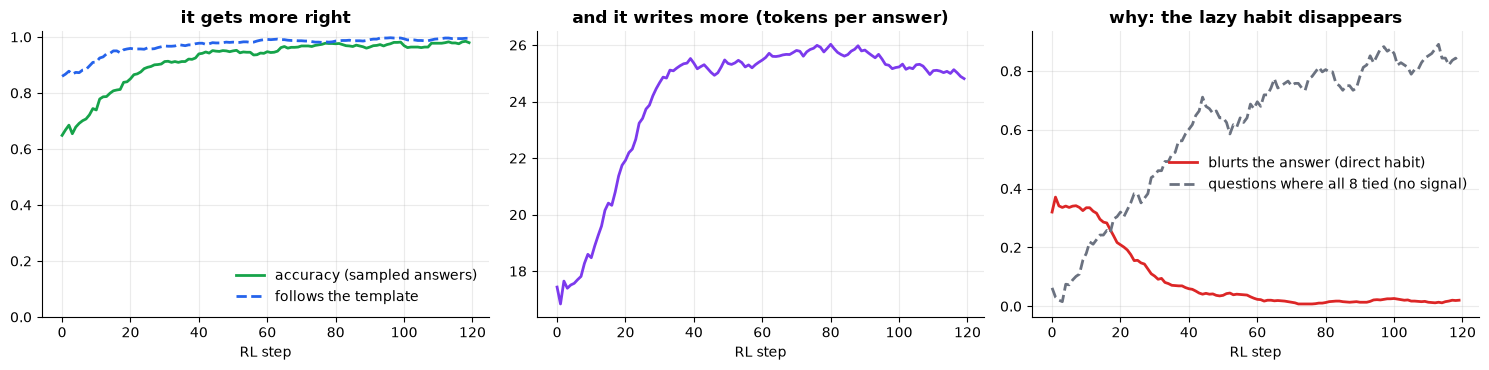

sampled accuracy 0.65 -> 0.98    length 17.4 -> 25.0 tokens    direct habit 0.32 -> 0.02


held-out test, 300 fresh problems: {'acc': 0.973, 'fmt': 1.0, 'length': 24.653, 'wait': 0.077, 'french': 0.263, 'direct': 0.017}    base was 0.626


In [14]:
def curve(hist, key, window=8):
    return smooth([h[key] for h in hist], window)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(curve(h_zero, "acc"), color=COLORS["reward"], lw=2, label="accuracy (sampled answers)")
ax[0].plot(curve(h_zero, "fmt"), color=COLORS["policy"], lw=2, ls="--", label="follows the template")
ax[0].set_title("it gets more right"); ax[0].set_xlabel("RL step"); ax[0].set_ylim(0, 1.02); ax[0].legend(loc="lower right")
ax[1].plot(curve(h_zero, "length"), color=COLORS["accent"], lw=2); ax[1].set_title("and it writes more (tokens per answer)"); ax[1].set_xlabel("RL step")
ax[2].plot(curve(h_zero, "direct"), color=COLORS["penalty"], lw=2, label="blurts the answer (direct habit)")
ax[2].plot(curve(h_zero, "zero_signal"), color=COLORS["reference"], lw=2, ls="--", label="questions where all 8 tied (no signal)")
ax[2].set_title("why: the lazy habit disappears"); ax[2].set_xlabel("RL step"); ax[2].legend(loc="center right")
plt.tight_layout(); plt.savefig(asset_path("r1_zero_curves.png"), bbox_inches="tight", dpi=110); plt.show()

before, after = h_zero[0], np.mean([[h[k] for k in ("acc", "length", "direct")] for h in h_zero[-10:]], axis=0)
print(f"sampled accuracy {before['acc']:.2f} -> {after[0]:.2f}    length {before['length']:.1f} -> {after[1]:.1f} tokens    direct habit {before['direct']:.2f} -> {after[2]:.2f}")
final = evaluate_policy(ZERO, tok)
print("held-out test, 300 fresh problems:", {k: round(v, 3) for k, v in final.items()}, "   base was", round(base_dash["acc"], 3))
assert final["acc"] > base_dash["acc"] + 0.2, "RL from the base model, with no demonstrations, must raise held-out accuracy a lot"
assert after[1] > before["length"] + 3, "responses get longer"
assert after[2] < 0.5 * before["direct"], "the answer-without-work habit is abandoned"

![R1-Zero response length](../../assets/rl/course/paper_r1_fig3_length_growth.png)

**📄 Fig. 3 (p. 8):** "The average response length of DeepSeek-R1-Zero on the training set during the RL process. DeepSeek-R1-Zero naturally learns to solve reasoning tasks with more thinking time."

**🧪 Finding.** Starting from a model that is right about 60 % of the time, accuracy climbs above 90 % with no demonstration of any kind, and the answers get longer. Both of the paper's pictures appear in miniature. The reason is clear in the third panel: the *direct* habit, short but unreliable, is squeezed out because answers written that way lose to their siblings, and the *steps* habit, longer but reliable, wins.

This is the paper's "self-evolution", and this is where we want to be careful about the word *emergence*:

* 💭 RL did not **invent** step-by-step working. The base model already wrote steps a third of the time. What RL did was **find out, from the reward alone, that steps pay**, and make it the default.
* The model also learned to *stop skipping the format*, and to be more careful inside each step (the fraction of wrong sums drops; we measure that in section 6).
* ⚠️ Real R1-Zero lengthens from hundreds to thousands of tokens and reportedly changes its *style* of reasoning. Our toy only has a few habits to choose between, so the growth is a jump between two modes rather than a drift.

### Which part of GRPO matters? Remove the group baseline.

A fair question about any algorithm: take away one piece and see what breaks. We keep everything else the same but replace the group-normalised advantage by the **raw reward** (no baseline at all):

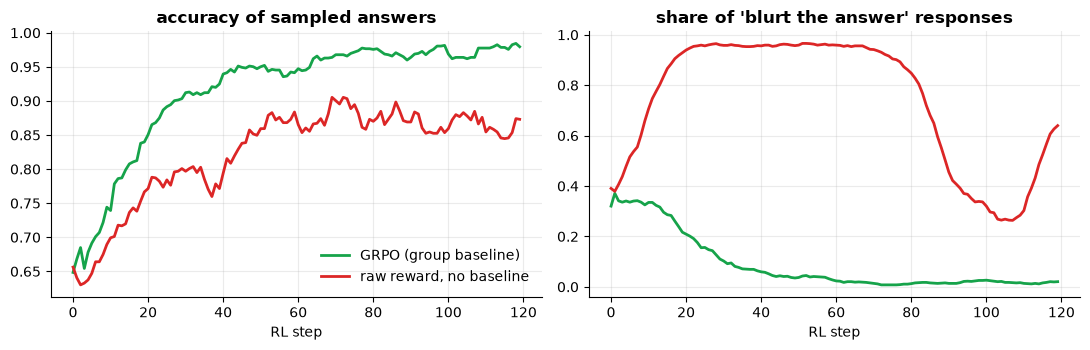

held-out accuracy:  with group baseline 0.973    raw reward 0.85
direct-habit share: with group baseline 0.017    raw reward 0.677


In [15]:
NOBASE, h_nobase, snaps_nobase = run_or_load("nobaseline_d96", BASE, reward_fn=make_reward(0.2, 0.0), steps=120, lr=2e-4, baseline="none")
fin_nb = evaluate_policy(NOBASE, tok)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for h, lab, c in ((h_zero, "GRPO (group baseline)", COLORS["reward"]), (h_nobase, "raw reward, no baseline", COLORS["penalty"])):
    ax[0].plot(curve(h, "acc"), color=c, lw=2, label=lab); ax[1].plot(curve(h, "direct"), color=c, lw=2, label=lab)
ax[0].set_title("accuracy of sampled answers"); ax[1].set_title("share of 'blurt the answer' responses")
for a in ax: a.set_xlabel("RL step")
ax[0].legend(); plt.tight_layout(); plt.show()
print("held-out accuracy:  with group baseline", round(final["acc"], 3), "   raw reward", round(fin_nb["acc"], 3))
print("direct-habit share: with group baseline", round(final["direct"], 3), "   raw reward", round(fin_nb["direct"], 3))
assert final["acc"] > fin_nb["acc"] + 0.1

**🧪 Finding (and a lesson that is easy to miss).** Without a baseline, training does **not** merely slow down; it goes somewhere worse. Held-out accuracy ends at 0.85 instead of 0.97, only about two thirds of the answers still follow the template, and the average answer *shrinks* to about 7 tokens: the model has collapsed toward the shortest, cheapest responses. Look at the reward: every answer that earns anything is pushed *up*, and short answers are the easiest to get right or get the format bonus on. 💭 Our reading is that with a raw, always-positive reward nothing ever says "this was worse than usual", so whatever is easy gets reinforced. The group baseline fixes this by making the question "better than your siblings?": a wrong answer in a group where others were right is below average, so it is pushed **down**, format or not.

> 💭 A baseline is not just a variance-reduction trick that makes learning smoother. When rewards are all positive, it is what makes "worse than average" mean "negative".

## 6. The "aha moment", and what it takes (📄 §2.2.4)

The most quoted moment in the paper is a single transcript from an intermediate R1-Zero checkpoint, in the middle of solving an equation:

![The aha moment](../../assets/rl/course/paper_r1_table3_aha_moment.png)

**📄 Table 3 (p. 9):** "An interesting 'aha moment' of an intermediate version of DeepSeek-R1-Zero. The model learns to rethink using an anthropomorphic tone. This is also an aha moment for us, allowing us to witness the power and beauty of reinforcement learning."

The model writes "Wait, wait. Wait. That's an aha moment I can flag here." and then re-does its work. The paper's reading: "rather than explicitly teaching the model on how to solve a problem, we simply provide it with the right incentives, and it autonomously develops advanced problem-solving strategies."

Can a toy say anything about that? Yes, but only about a narrower question: **under what conditions would a "wait, let me redo that" habit pay off?** Our miniature internet contains authors who write `wait` after noticing a slip. For RL to promote that habit, two things must be true:

1. The model must be able to **tell when it slipped**. Writing `wait` after a *right* sum wastes tokens.
2. The redo must be **more likely right** than the original.

We can measure the first directly: after the model writes a sum, how often does it write `wait` when the sum was wrong versus right?

In [16]:
det_big, det_small = slip_detection(BASE, tok), slip_detection(SMALL, tok)
print(f"{'':14s} {'P(wait | sum was WRONG)':>26s} {'P(wait | sum was right)':>26s}")
for name, d in (("small base", det_small), ("big base", det_big)):
    print(f"{name:14s} {d['p_wait_after_wrong']:26.1%} {d['p_wait_after_right']:26.1%}   ({d['n_wrong']} wrong sums seen)")

                  P(wait | sum was WRONG)    P(wait | sum was right)
small base                           9.9%                      10.1%   (405 wrong sums seen)
big base                            38.9%                       1.8%   (270 wrong sums seen)


The small base model writes `wait` just as often after right sums as after wrong ones. It **cannot** check its own arithmetic, so its `wait` is noise. The bigger base model writes `wait` far more often after a wrong sum than after a right one: it *can* notice. Now we let RL loose on both and watch what happens to the habit:

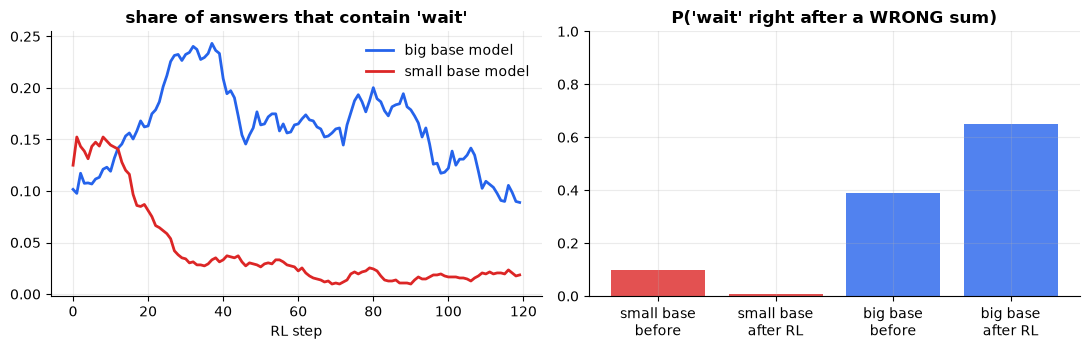

'wait' share at the end of RL:  small model 0.02   big model 0.10


wrong-sum rate (share of written sums that are wrong) before -> after, big model: 0.166 -> 0.036


In [17]:
SMALL_RL, h_small, _ = run_or_load("zero_d64", SMALL, reward_fn=make_reward(0.2, 0.0), steps=120, lr=3e-4)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for h, lab, c in ((h_zero, "big base model", COLORS["policy"]), (h_small, "small base model", COLORS["penalty"])):
    ax[0].plot(curve(h, "wait"), color=c, lw=2, label=lab)
ax[0].set_title("share of answers that contain 'wait'"); ax[0].set_xlabel("RL step"); ax[0].legend()
labels = ["small base\nbefore", "small base\nafter RL", "big base\nbefore", "big base\nafter RL"]
vals = [det_small["p_wait_after_wrong"], slip_detection(SMALL_RL, tok)["p_wait_after_wrong"], det_big["p_wait_after_wrong"], slip_detection(ZERO, tok)["p_wait_after_wrong"]]
ax[1].bar(labels, vals, color=[COLORS["penalty"]] * 2 + [COLORS["policy"]] * 2, alpha=0.8)
ax[1].set_title("P('wait' right after a WRONG sum)"); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

wait_small_end, wait_big_end = np.mean([h["wait"] for h in h_small[-10:]]), np.mean([h["wait"] for h in h_zero[-10:]])
print(f"'wait' share at the end of RL:  small model {wait_small_end:.2f}   big model {wait_big_end:.2f}")
print("wrong-sum rate (share of written sums that are wrong) before -> after, big model:",
      f"{det_big['n_wrong'] / (det_big['n_wrong'] + det_big['n_right']):.3f} ->",
      f"{(lambda d: d['n_wrong'] / (d['n_wrong'] + d['n_right']))(slip_detection(ZERO, tok)):.3f}")
assert det_big["p_wait_after_wrong"] > 5 * det_big["p_wait_after_right"], "the big base model can tell when it slipped"
assert det_small["p_wait_after_wrong"] < 2 * det_small["p_wait_after_right"], "the small one cannot"
assert wait_big_end > wait_small_end + 0.05, "the 'wait' habit survives RL only where it carries information"

**🧪 Finding.** In the big model the `wait` habit **survives** RL and is used selectively, mostly right after a mistake. In the small model it is pruned: the same reward that kept it in one model removed it from the other, because for the small model a `wait` is just a longer answer with no benefit.

**💭 What this does and does not tell us.**

* The toy supports a modest statement: **a self-check habit can be rewarded into existence only if the base model can already tell right from wrong often enough to benefit.** That is plausibly one reason R1-Zero was run on a very large base model. The paper does not make that argument; we do.
* It does **not** show *emergence* of reflection from nothing. Our corpus contains the habit; RL decided how much of it to keep. In the paper's example the model's "wait" arrives in a model that had read a lot of text, probably including people re-checking their work. We are not claiming otherwise.
* ⚠️ Even in the big toy model the `wait` share does not grow: it ends where it started (about 10 % of answers) while the share of wrong sums falls from about 17 % to 4 %, so there are simply fewer slips to catch. The paper's aha moment is a qualitative, single-transcript observation; reproducing "the model's tone changes" needs a language model, not a calculator.

## 7. Measuring a model that answers differently every time (📄 §3)

Once a model samples, "is it correct?" is no longer a yes/no question. Ask the same problem twice and you may get two answers. R1's evaluation section makes three small decisions that are easy to skim past, and each is worth understanding.

**Decision 1: do not use greedy decoding.** 📄 "We found that using greedy decoding to evaluate long-output reasoning models results in higher repetition rates and significant variability across different checkpoints." They instead sample at temperature 0.6 with top-p 0.95, generate $k$ responses (4 to 64 per problem) and report **pass@1** as the *average correctness*:

$$\text{pass@1} = \frac1k\sum_{i=1}^{k} p_i, \qquad p_i \in \{0,1\}.$$

**Decision 2: report consensus.** For AIME they also report **cons@64**: sample 64 answers, take the **most common final answer** ("majority vote"), and score that. 📄 In Table 2, R1-Zero's AIME goes "from 71.0% to 86.7%" this way.

![R1-Zero vs o1 (Table 2)](../../assets/rl/course/paper_r1_table2_r1zero.png)

**📄 Table 2 (p. 7):** "Comparison of DeepSeek-R1-Zero and OpenAI o1 models on reasoning-related benchmarks."

**Decision 3: also know pass@k.** The *chance that at least one of k samples is right* (the standard code-generation metric) answers a different question: "could this model get it with a few tries and an oracle to pick?" A careful estimator uses $n \ge k$ samples per problem and computes $1 - \binom{n-c}{k}/\binom{n}{k}$, with $c$ the number correct. Let us build all three, and *check the estimator against brute force*:

In [18]:
from math import comb
from itertools import combinations

def pass_at_k(n: int, c: int, k: int) -> float:
    """Unbiased probability that at least one of k answers drawn from n samples (c correct) is correct."""
    return 1.0 if n - c < k else 1.0 - comb(n - c, k) / comb(n, k)

def consensus(answers: list):
    """Majority vote over final answers (None = unparseable, which can win only if nothing else is more common)."""
    return collections.Counter(answers).most_common(1)[0][0]

# brute-force check on a tiny case: n=6 samples, 2 correct, k=3
flags = [1, 1, 0, 0, 0, 0]
brute = np.mean([any(flags[i] for i in s) for s in combinations(range(6), 3)])
print("pass@3 closed form", round(pass_at_k(6, 2, 3), 4), "  by enumerating all 20 triples", round(float(brute), 4))
assert abs(pass_at_k(6, 2, 3) - brute) < 1e-12
assert consensus([47, 46, 47, None, 47]) == 47

pass@3 closed form 0.8   by enumerating all 20 triples 0.8


Now measure the R1-Zero model with all three on 120 held-out problems, 64 samples each (at the paper's temperature 0.6 *and* at 1.0), and compare with greedy:

(137s)   greedy 0.997   pass@1 at T=1.0 0.946   pass@1 at T=0.6 0.974


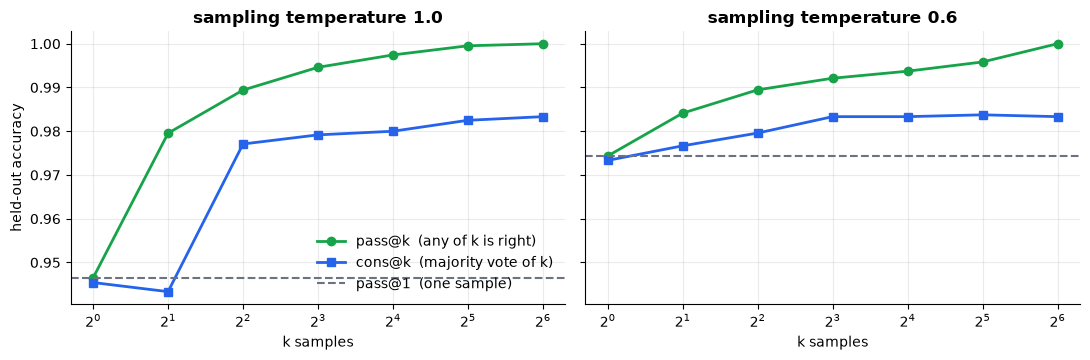

In [19]:
def collect(model, n_problems=120, n_samples=64, temperature=1.0, seed=77):
    qs = ProblemSet(seed).sample(n_problems, "test"); out = []
    for q in qs:
        res = rollout(model, tok, [q] * n_samples, temperature)[3]
        out.append((q, [r["answer"] for r in res]))
    return out

def score_curves(collected, ks=(1, 2, 4, 8, 16, 32, 64), draws=20, rng=np.random.default_rng(0)):
    p1, pk, ck = [], {k: [] for k in ks}, {k: [] for k in ks}
    for q, answers in collected:
        n, c = len(answers), sum(a == q.gold for a in answers)
        p1.append(c / n)
        for k in ks:
            pk[k].append(pass_at_k(n, c, k))
            ck[k].append(np.mean([consensus(list(rng.choice(answers, k, replace=False))) == q.gold for _ in range(draws)]))
    return float(np.mean(p1)), {k: float(np.mean(v)) for k, v in pk.items()}, {k: float(np.mean(v)) for k, v in ck.items()}

t0 = time.time()
col_t1, col_t06 = collect(ZERO, temperature=1.0), collect(ZERO, temperature=0.6)
p1_a, pk_a, ck_a = score_curves(col_t1); p1_b, pk_b, ck_b = score_curves(col_t06)
greedy = evaluate_policy(ZERO, tok, n=300, greedy=True)["acc"]
print(f"({time.time() - t0:.0f}s)   greedy {greedy:.3f}   pass@1 at T=1.0 {p1_a:.3f}   pass@1 at T=0.6 {p1_b:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.7), sharey=True)
for a, (pk, ck, p1, T) in zip(ax, ((pk_a, ck_a, p1_a, 1.0), (pk_b, ck_b, p1_b, 0.6))):
    ks = sorted(pk)
    a.plot(ks, [pk[k] for k in ks], "o-", color=COLORS["reward"], lw=2, label="pass@k  (any of k is right)")
    a.plot(ks, [ck[k] for k in ks], "s-", color=COLORS["policy"], lw=2, label="cons@k  (majority vote of k)")
    a.axhline(p1, color=COLORS["reference"], ls="--", label="pass@1  (one sample)"); a.set_xscale("log", base=2)
    a.set_title(f"sampling temperature {T}"); a.set_xlabel("k samples")
ax[0].set_ylabel("held-out accuracy"); ax[0].legend(loc="lower right"); plt.tight_layout(); plt.show()
assert ck_a[16] > p1_a + 0.005 and ck_a[64] >= ck_a[1] - 0.02, "majority vote helps (or at least does not hurt)"
assert all(pk_a[k] >= p1_a - 1e-9 for k in pk_a) and pk_a[64] >= ck_a[64] - 1e-9, "pass@k is an upper bound on consensus"

**🧪 Finding.** The three numbers answer three different questions:

* **pass@1** is the honest "how often is a single answer right?", an average over its own randomness.
* **cons@k** is "can the model's *consensus* be trusted?". It rises because wrong answers are scattered (many different mistakes) while the right answer repeats. The paper's AIME jump from 71.0 % to 86.7 % is this effect at scale.
* **pass@k** is the ceiling that a perfect picker could reach; it is always the largest.

On greedy decoding, our toy is *not* where the paper's warning shows: greedy scores about 0.997 here against 0.946 (T=1.0) and 0.974 (T=0.6) for sampling, because our answers are short and cannot loop. ⚠️ The paper's repetition problem is about thousand-token chains; a 30-token answer cannot repeat itself into trouble. We report the number rather than pretend we reproduced the claim.

## 8. R1-Zero's problems, and the cold start (📄 §2.3.1)

R1-Zero is a proof of concept, not a product. 📄 The paper says: "DeepSeek-R1-Zero struggles with challenges like poor readability, and language mixing." Our version of language mixing is the French connector. Let us look at what R1-Zero left behind, and at the one question the authors ask next:

> 📄 "1) Can reasoning performance be further improved or convergence accelerated by incorporating a small amount of high-quality data as a cold start? 2) How can we train a user-friendly model that not only produces clear and coherent Chains of Thought (CoT) but also demonstrates strong general capabilities?"

In [20]:
raw = [r for r in rollout(ZERO, tok, PS.sample(400, "test"))[3]]
mixed = [r for r in raw if r["n_fr"] > 0]
print(f"after R1-Zero-style RL: {len(mixed) / len(raw):.0%} of answers still contain a French connector, {1 - np.mean([r['format_ok'] for r in raw]):.1%} break the template")
for r in mixed[:3]: print("   ", r["text"])

after R1-Zero-style RL: 24% of answers still contain a French connector, 0.5% break the template
    <think> 30+14=44 puis 44+06=50 </think> <answer> 50 </answer>
    <think> 15+09=24 puis 24+26=50 </think> <answer> 50 </answer>
    <think> 06+24=30 puis 30+03=33 </think> <answer> 33 </answer>


Nothing in the reward mentions language, so nothing pushes it down. It even *grew* (12 % of base answers had a French connector, now about a quarter): 💭 the *steps* habit, which contains connectors, replaced the *direct* habit, which contains none, so there are more chances for a French one. The **cold start** is the paper's first fix. 📄 "To prevent the early unstable cold start phase of RL training from the base model, for DeepSeek-R1 we construct and collect a small amount of long CoT data to fine-tune the model as the initial RL actor." Thousands of clean, readable examples, collected by prompting a model with a long-CoT example, by taking R1-Zero outputs "in a readable format", and by human clean-up. They also fix a **readable output pattern** (a reasoning block followed by a summary).

Our cold start is the same move in miniature: a *few hundred* clean documents (English only, template always followed, steps always correct), then ordinary supervised fine-tuning. This is the one place where we use the miniature internet's author as a **teacher** instead of a corpus.

In [21]:
def sft_on_documents(model, make_batch, steps, lr=1e-3):
    """Plain supervised learning: next-token cross-entropy on the response (the prompt is masked out)."""
    prompt_len = encode_prompts(tok, [Problem(0, 0, 0)]).shape[1]
    sft_train(model, make_batch, steps=steps, lr=lr, prompt_len=prompt_len)
    return model.eval()

CLEAN = CorpusWriter(3, p_direct=0, p_steps=1, p_sloppy_format=0, p_french=0, step_err=0)     # the "annotator": careful, English, templated
cold_path = CACHE / "coldstart_d96.pt"
COLD = make_model(tok, 96); COLD.load_state_dict(BASE.state_dict())
if cold_path.exists():
    COLD.load_state_dict(torch.load(cold_path))
else:
    qs = ProblemSet(11)
    sft_on_documents(COLD, lambda: CLEAN.batch(tok, qs.sample(16)), steps=20)            # 20 x 16 = 320 clean examples
    torch.save(COLD.state_dict(), cold_path)
COLD.eval()
cold_dash = evaluate_policy(COLD, tok)
print("after cold-start SFT (320 clean examples, before any RL):", {k: round(v, 3) for k, v in cold_dash.items()})
print("base model                                              :", {k: round(v, 3) for k, v in base_dash.items()})
assert cold_dash["french"] < 0.5 * base_dash["french"] and cold_dash["fmt"] > base_dash["fmt"], "cold start fixes readability before RL starts"

after cold-start SFT (320 clean examples, before any RL): {'acc': 0.903, 'fmt': 0.997, 'length': 24.167, 'wait': 0.003, 'french': 0.003, 'direct': 0.0}
base model                                              : {'acc': 0.626, 'fmt': 0.846, 'length': 17.132, 'wait': 0.1, 'french': 0.125, 'direct': 0.342}


Even this tiny amount of clean data does two things before any RL: the template is followed and the French all but vanishes, i.e. **readability is baked in at the starting line** instead of being hoped for. Does it also change how RL goes? We run the same RL from the cold-started model and put the two starts on one plot:

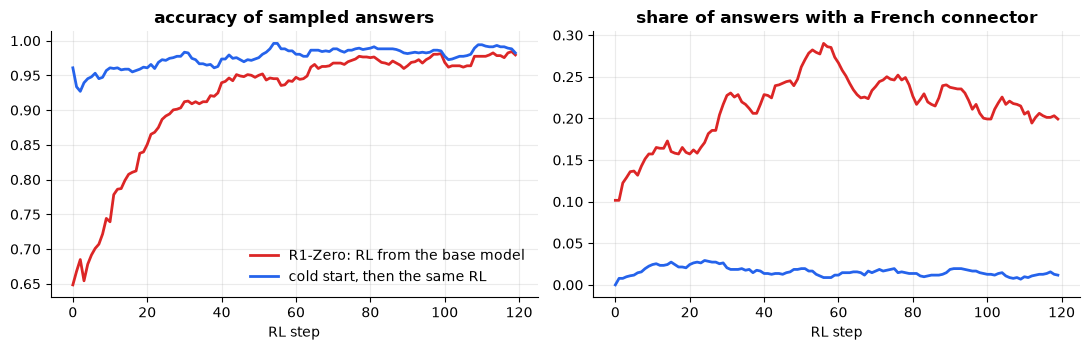

RL steps until sampled accuracy reaches 0.9:   R1-Zero 27    cold start 0
held-out accuracy after RL:   R1-Zero 0.973   cold start 0.983
French connector after RL:    R1-Zero 0.263   cold start 0.017


In [22]:
COLD_RL, h_cold, _ = run_or_load("cold_rl_d96", COLD, reward_fn=make_reward(0.2, 0.0), steps=120, lr=2e-4)

def steps_to(hist, thr=0.9, key="acc", window=8):
    c = smooth([h[key] for h in hist], window)
    return next((i for i, v in enumerate(c) if v >= thr), None)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for h, lab, c in ((h_zero, "R1-Zero: RL from the base model", COLORS["penalty"]), (h_cold, "cold start, then the same RL", COLORS["policy"])):
    ax[0].plot(curve(h, "acc"), color=c, lw=2, label=lab); ax[1].plot(curve(h, "french"), color=c, lw=2, label=lab)
ax[0].set_title("accuracy of sampled answers"); ax[1].set_title("share of answers with a French connector")
for a in ax: a.set_xlabel("RL step")
ax[0].legend(loc="lower right"); plt.tight_layout(); plt.show()
fin_cold = evaluate_policy(COLD_RL, tok)
print(f"RL steps until sampled accuracy reaches 0.9:   R1-Zero {steps_to(h_zero)}    cold start {steps_to(h_cold)}")
print(f"held-out accuracy after RL:   R1-Zero {final['acc']:.3f}   cold start {fin_cold['acc']:.3f}")
print(f"French connector after RL:    R1-Zero {final['french']:.3f}   cold start {fin_cold['french']:.3f}")
assert fin_cold["french"] < final["french"], "cold start keeps the output readable"
assert (steps_to(h_cold) or 0) <= (steps_to(h_zero) or 10**9), "cold start reaches the same accuracy no later"

**🧪 Finding.** The cold start does what the paper claims for it: RL starts from a better place, so it converges sooner, and the output stays readable. On accuracy alone the two end up close. ⚠️ We need to be honest about the toy here: we could write a *perfect* teacher in two lines of code (`CLEAN`), so cold-start data is free for us. In the real setting such data (long, correct, readable reasoning) is **scarce and expensive**, which is exactly why R1 uses only thousands of examples and still relies on RL for everything beyond them.

## 9. The language-consistency reward (📄 §2.3.2)

Cold start helps, but RL still *drifts*: a model that is only rewarded for being right has no reason to prefer English over French. The paper's second fix is a term in the reward:

> 📄 "To mitigate the issue of language mixing, we introduce a language consistency reward during RL training, which is calculated as the proportion of target language words in the CoT. Although ablation experiments show that such alignment results in a slight degradation in the model's performance, this reward aligns with human preferences, making it more readable. [...] we combine the accuracy of reasoning tasks and the reward for language consistency by directly summing them to form the final reward."

We already wrote `language_reward` in section 2: the share of English connector words among all connector words. Add it to the reward with weight 0.2 and train from the *base* model (to isolate its effect, with no cold start):

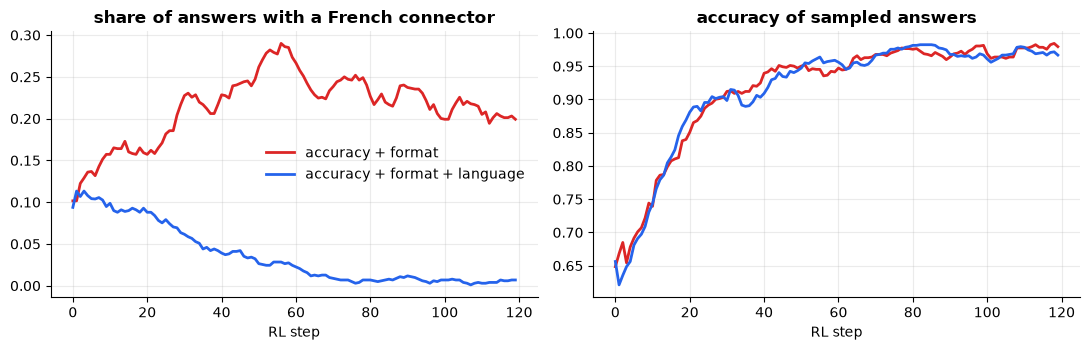

French connector:  without 0.263   with language reward 0.003
held-out accuracy: without 0.973   with language reward 0.957


In [23]:
LANG, h_lang, _ = run_or_load("lang_d96", BASE, reward_fn=make_reward(0.2, 0.2), steps=120, lr=2e-4)
fin_lang = evaluate_policy(LANG, tok)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for h, lab, c in ((h_zero, "accuracy + format", COLORS["penalty"]), (h_lang, "accuracy + format + language", COLORS["policy"])):
    ax[0].plot(curve(h, "french"), color=c, lw=2, label=lab); ax[1].plot(curve(h, "acc"), color=c, lw=2, label=lab)
ax[0].set_title("share of answers with a French connector"); ax[1].set_title("accuracy of sampled answers")
for a in ax: a.set_xlabel("RL step")
ax[0].legend(); plt.tight_layout(); plt.show()
print(f"French connector:  without {final['french']:.3f}   with language reward {fin_lang['french']:.3f}")
print(f"held-out accuracy: without {final['acc']:.3f}   with language reward {fin_lang['acc']:.3f}")
assert fin_lang["french"] < 0.3 * final["french"] + 0.01, "the language term removes the mixing"
assert fin_lang["acc"] > final["acc"] - 0.05, "...at (almost) no cost in accuracy in this toy"

**🧪 Finding.** One extra term and the mixing disappears (from about a quarter of answers to 0.3 %). The paper reports a *slight* accuracy cost; we see a similarly slight one, 0.957 against 0.973, about the size of the noise in a 300-problem test (⚠️ the toy cannot say more: our French word is as correct as the English one, it just isn't wanted. In a real model, forcing the "thinking language" can constrain a useful thought process).

> 💭 The general lesson goes beyond language. RL optimises exactly what you score. Whatever you care about and do not score, from readability to length to politeness, will drift. A reward term is how you tell the optimiser that something matters, and a small weight is often enough, because it only has to break ties between answers that are equally correct.

## 10. From RL output to training data: rejection sampling and SFT (📄 §2.3.3)

After reasoning-RL converges, R1 does something that looks backwards at first: it uses the RL model to **write a new supervised dataset**, then trains on it again. 📄 "We curate reasoning prompts and generate reasoning trajectories by performing rejection sampling from the checkpoint from the above RL training. [...] For each prompt, we sample multiple responses and retain only the correct ones. In total, we collect about 600k reasoning related training samples." They also filter for readability ("chain-of-thought with mixed languages, long paragraphs, and code blocks") and add about 200k non-reasoning samples (writing, factual QA, self-cognition, translation). The base model is then fine-tuned for two epochs on the ~800k samples.

**Rejection sampling** is the plainest idea in the paper: sample many answers, **keep the ones that pass the checks, throw the rest away**. No gradient, no reward shaping.

Why do it, when the model is already trained by RL? 💭 Three plausible reasons: (a) RL samples are *noisy* and the survivors are a clean, curated slice; (b) supervised learning on a good dataset is stable and cheap, and can be mixed with other kinds of data (here: the non-reasoning set); (c) the dataset can be reused to train *other* models (that is §11).

We implement it as the paper describes, with our own readability filter (correct, template followed, no French):

In [24]:
def rejection_sample(teacher, n_questions=900, K=8, keep_per_question=2, seed=21):
    """Sample K answers per question, keep up to `keep_per_question` that are correct AND readable."""
    qs = ProblemSet(seed).sample(n_questions); kept, tried = [], 0
    for i in range(0, n_questions, 50):
        chunk = qs[i:i + 50]
        group = [q for q in chunk for _ in range(K)]
        _, _, P, parsed = rollout(teacher, tok, group)
        tried += len(parsed)
        per_q = collections.defaultdict(list)
        for q, o in zip(group, parsed):
            if o["answer"] == q.gold and o["format_ok"] and o["n_fr"] == 0:        # the filters
                per_q[q].append(o["ids"])
        for q, answers in per_q.items():
            kept += [(q, a) for a in answers[:keep_per_question]]
    return kept, tried

rs_path = CACHE / "rejection_sampled.pt"
if rs_path.exists():
    traces, tried = torch.load(rs_path, weights_only=False)
else:
    traces, tried = rejection_sample(LANG); torch.save((traces, tried), rs_path)
print(f"sampled {tried:,} answers, kept {len(traces):,} ({len(traces) / tried:.0%}) for {len({q for q, _ in traces}):,} questions")
for q, ids in traces[:2]: print(f"   Q {q.a:02d}+{q.b:02d}+{q.c:02d}= -> {tok.pretty(ids)}")

sampled 7,200 answers, kept 1,791 (25%) for 893 questions
   Q 10+40+26= -> <think> 10+40=50 then 50+26=76 </think> <answer> 76 </answer>
   Q 10+40+26= -> <think> 10+40=50 then 50+26=76 </think> <answer> 76 </answer>


Now we turn those traces into a supervised dataset and fine-tune. As in the paper we start from the **base model**, not from the RL checkpoint:

In [25]:
def traces_to_batch(traces, size=64, rng=random.Random(0)):
    rows = []
    for q, ids in rng.sample(traces, size):
        rows.append([tok.BOS] + tok.ids(q.prompt_tokens()) + ids)      # ids already ends with <eos>
    L = max(map(len, rows))
    return torch.tensor([r + [tok.PAD] * (L - len(r)) for r in rows])

SFT800K = make_model(tok, 96); SFT800K.load_state_dict(BASE.state_dict())
sft_path = CACHE / "sft_on_rs_d96.pt"
if sft_path.exists():
    SFT800K.load_state_dict(torch.load(sft_path))
else:
    sft_on_documents(SFT800K, lambda: traces_to_batch(traces), steps=300, lr=1e-3); torch.save(SFT800K.state_dict(), sft_path)
SFT800K.eval()
fin_sft = evaluate_policy(SFT800K, tok)
print("base                       :", round(base_dash["acc"], 3))
print("RL teacher (section 9)     :", round(fin_lang["acc"], 3), "  French", round(fin_lang["french"], 3))
print("SFT on rejection-sampled   :", round(fin_sft["acc"], 3), "  French", round(fin_sft["french"], 3), "  template", round(fin_sft["fmt"], 3))
assert fin_sft["acc"] > base_dash["acc"] + 0.15 and fin_sft["french"] < 0.05, "supervised learning on the filtered samples recovers the RL skill, readably"

base                       : 0.626
RL teacher (section 9)     : 0.957   French 0.003
SFT on rejection-sampled   : 0.967   French 0.0   template 1.0


**🧪 Finding.** A model that has *never* been through RL, trained only to imitate the filtered samples of one that was, gets most of the way to the RL model's accuracy, with clean output. The reasoning skill has been moved from "something found by trial and error" into "something to imitate", which is exactly what makes the next section possible.

**The last RL stage (📄 §2.3.4) we only describe.** R1 then runs RL again over *all* scenarios. For reasoning it keeps the rule-based rewards. For general chat it uses reward models: "For helpfulness, we focus exclusively on the final summary, [...] For harmlessness, we evaluate the entire response of the model, including both the reasoning process and the summary." Reproducing that needs human-preference data and a reward model; our world has neither, so we stop here rather than fake it. ⚠️

## 11. Distillation beats RL for small models (📄 §2.4, §4.1)

R1 itself is huge. The models people actually run are the six **distilled** ones (1.5B to 70B parameters). They were made *without RL*: the authors "directly fine-tuned open-source models like Qwen and Llama using the 800k samples curated with DeepSeek-R1". 📄 Only SFT, "even though incorporating RL could substantially boost model performance".

The surprising part is the comparison in the Discussion section. They took a 32B base model and did the full R1-Zero style RL on it for over 10,000 steps, then compared it to simply fine-tuning the same base on R1's samples:

![Distillation versus RL](../../assets/rl/course/paper_r1_table6_distill_vs_rl.png)

**📄 Table 6 (p. 15):** "Comparison of distilled and RL Models on Reasoning-Related Benchmarks." On AIME 2024 pass@1 the RL-trained 32B model scores **47.0**, the distilled 32B model **72.6**.

The paper draws two conclusions: "distilling more powerful models into smaller ones yields excellent results, whereas smaller models relying on the large-scale RL [...] require enormous computational power and may not even achieve the performance of distillation. Second, [...] advancing beyond the boundaries of intelligence may still require more powerful base models and larger-scale reinforcement learning."

We can run the same experiment, small. The student is our *small* model. Two ways to teach it, from the same starting point:

* **RL on the small model**, the same recipe as before (we already trained it in section 6: `SMALL_RL`).
* **Distillation**: fine-tune the small model on the big teacher's filtered samples (the same traces as section 10).

In [26]:
DIST = make_model(tok, 64); DIST.load_state_dict(SMALL.state_dict())
dist_path = CACHE / "distilled_d64.pt"
if dist_path.exists():
    DIST.load_state_dict(torch.load(dist_path))
else:
    sft_on_documents(DIST, lambda: traces_to_batch(traces), steps=300, lr=1e-3); torch.save(DIST.state_dict(), dist_path)
DIST.eval()

rows = {"small base (before anything)": evaluate_policy(SMALL, tok),
        "small + RL (R1-Zero recipe)": evaluate_policy(SMALL_RL, tok),
        "small + distillation (SFT on the big teacher's samples)": evaluate_policy(DIST, tok),
        "big teacher (for reference)": fin_lang}
print(f"{'':58s} {'accuracy':>9s} {'template':>9s} {'French':>7s}")
for k, d in rows.items():
    print(f"{k:58s} {d['acc']:9.3f} {d['fmt']:9.3f} {d['french']:7.3f}")
print(f"\nparameters: student {count_parameters(SMALL):,}   teacher {count_parameters(BASE):,}")

                                                            accuracy  template  French
small base (before anything)                                   0.377     0.863   0.143
small + RL (R1-Zero recipe)                                    0.927     0.997   0.190
small + distillation (SFT on the big teacher's samples)        0.917     0.997   0.000
big teacher (for reference)                                    0.957     0.993   0.003

parameters: student 109,696   teacher 238,272


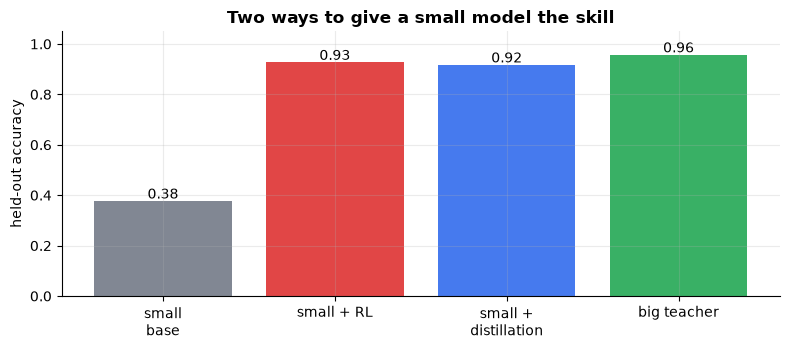

In [27]:
fig, ax = plt.subplots(figsize=(8, 3.6))
names = ["small\nbase", "small + RL", "small +\ndistillation", "big teacher"]
vals = [d["acc"] for d in rows.values()]
bars = ax.bar(names, vals, color=[COLORS["reference"], COLORS["penalty"], COLORS["policy"], COLORS["reward"]], alpha=0.85)
for b, v in zip(bars, vals): ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center")
ax.set_ylim(0, 1.05); ax.set_ylabel("held-out accuracy"); ax.set_title("Two ways to give a small model the skill")
plt.tight_layout(); plt.show()

**🧪 Finding.** The paper's headline here is **not reproduced** in our toy, and it is worth saying so plainly. The distilled student (0.917) and the RL-trained student (0.927) end up with the same accuracy, within evaluation noise, and both are far above the untrained student (0.377). Two differences remain: distillation gives clean output (no French) where the RL student keeps its French connectors (0.19), and it never needs the student to sample and score its own answers. ⚠️ Why the gap the paper sees does not appear: our task is easy enough that even the small model's RL finds the good habit within 120 steps. The paper's RL student needed more than 10,000 steps and still trailed the distilled one by 25 AIME points. The toy supports the *mechanism* (the teacher's traces transfer the skill, readably) and not the *size* of the advantage.

> 💭 Why does the distilled student do better in the paper? A plausible reading, and the one the authors give: the teacher's samples contain the *reasoning patterns the big model discovered*. A small model doing RL on its own has to rediscover them by trial and error, and it can only discover what it already, occasionally, does. Distillation hands it the finished patterns. The second half of their conclusion, though, is important: distillation can only reach what the teacher can do. Past that, you need a better teacher, i.e. more RL on a larger base.

## 12. What did not work: process rewards and tree search (📄 §4.2)

A paper that reports its dead ends is rare, and this section of R1 is probably as influential as its successes: it tells everyone which "obvious" doors are not worth opening first. The authors are careful: "this does not imply that these approaches are incapable of developing effective reasoning models."

### 12.1 Process reward models (PRM)

An **outcome** reward only looks at the final answer. A **process reward model** scores *each step* of the reasoning, which sounds strictly better: you can tell the model *where* it went wrong. 📄 The three objections in the paper:

1. "it is challenging to explicitly define a fine-grain step in general reasoning."
2. "determining whether the current intermediate step is correct is a challenging task. Automated annotation using models may not yield satisfactory results, while manual annotation is not conducive to scaling up."
3. "once a model-based PRM is introduced, it inevitably leads to reward hacking, and retraining the reward model needs additional training resources and it complicates the whole training pipeline."

The conclusion they reach is balanced: a PRM has "a good ability to rerank the top-N responses generated by the model or assist in guided search", but its "advantages are limited compared to the additional computational overhead".

Our toy is unusually friendly to PRMs, because **a step is well defined** (`x+y=z`) and we *can* check it exactly. So objection 1 and half of 2 are removed by construction (⚠️). What we can test is the realistic remainder: the labels a PRM trains on are never perfect. We train a small PRM on step labels with **15 % label noise** (a stand-in for imperfect annotation), then use it two ways: to *rerank* samples, and as the *training reward*.

In [28]:
def split_steps(par):
    """(prefix token count, step_is_correct) for every x+y=z step in a parsed response (prefix = response tokens up to the step's end)."""
    names = [tok.itos[i] for i in par["ids"]]
    out, cur_start, cur = [], 0, []
    for j, t in enumerate(names):
        if t in (EN, FR, WAIT, END_THINK):
            m = re.fullmatch(r"(\d+)\+(\d+)=(\d+)", "".join(cur))
            if m: out.append((j, int(m.group(1)) + int(m.group(2)) == int(m.group(3))))
            cur = []
        else:
            cur.append(t)
    return out

class PRM(nn.Module):
    """A process reward model: a small transformer that reads  prompt + reasoning-so-far  and outputs P(this step is right)."""
    def __init__(self, d_model=64):
        super().__init__(); self.lm = make_model(tok, d_model); self.head = ValueHead(d_model)
    def forward(self, ids, last):                       # ids (B, T) right-padded; last (B,) index of the step's final token
        _, h = self.lm(ids)
        return self.head(h[torch.arange(ids.shape[0]), last])           # logit per row

def prm_rows(parsed, problems):
    """One training/scoring row per step: (token ids of prompt + response up to the step, index of its last token, true label)."""
    rows = []
    for o, q in zip(parsed, problems):
        if not o["format_ok"]: continue
        pr = [tok.BOS] + tok.ids(q.prompt_tokens())
        for j, ok in split_steps(o):
            rows.append((pr + o["ids"][:j], len(pr) + j - 1, ok))
    return rows

def pad_rows(rows):
    L = max(len(r[0]) for r in rows)
    ids = torch.tensor([r[0] + [tok.PAD] * (L - len(r[0])) for r in rows])
    return ids, torch.tensor([r[1] for r in rows]), torch.tensor([float(r[2]) for r in rows])

prm_path = CACHE / "prm_d64.pt"
PRM_NET = PRM(64)
if prm_path.exists():
    PRM_NET.load_state_dict(torch.load(prm_path))
else:
    qs = ProblemSet(31); data = []
    for _ in range(6):
        group = qs.sample(300); data += prm_rows(rollout(BASE, tok, group)[3], group)
    train_rows = data[: int(0.85 * len(data))]
    flip = random.Random(0)
    noisy = [(a, b, (not c) if flip.random() < 0.15 else c) for a, b, c in train_rows]            # 15% label noise
    opt = torch.optim.Adam(PRM_NET.parameters(), lr=2e-3)
    for it in range(500):
        ids, last, y = pad_rows(random.sample(noisy, 128))
        loss = F.binary_cross_entropy_with_logits(PRM_NET(ids, last), y); opt.zero_grad(); loss.backward(); opt.step()
    torch.save(PRM_NET.state_dict(), prm_path)
PRM_NET.eval()
test_rows = prm_rows(*(lambda g: (rollout(BASE, tok, g)[3], g))(ProblemSet(32).sample(400)))
with torch.no_grad():
    ids, last, y = pad_rows(test_rows); pred = (torch.sigmoid(PRM_NET(ids, last)) > 0.5).float()
print(f"PRM accuracy on {len(test_rows)} held-out steps with TRUE labels: {(pred == y).float().mean():.1%}   (share of steps that are actually right: {y.mean():.1%})")

PRM accuracy on 222 held-out steps with TRUE labels: 86.5%   (share of steps that are actually right: 87.8%)


**Use 1: reranking.** Sample 8 answers per question from the base model, and pick the one whose *weakest step* the PRM likes best. Compare with picking at random, and with the best a perfect picker could do:

In [29]:
def prm_step_scores(parsed, problems):
    """For each response: list of PRM probabilities of its steps (empty if it has none)."""
    rows = prm_rows(parsed, problems); owners = [i for i, (o, q) in enumerate(zip(parsed, problems)) if o["format_ok"] for _ in split_steps(o)]
    out = [[] for _ in parsed]
    if rows:
        with torch.no_grad():
            ids, last, _ = pad_rows(rows); pr = torch.sigmoid(PRM_NET(ids, last)).tolist()
        for i, s in zip(owners, pr): out[i].append(s)
    return out

qs = ProblemSet(41).sample(150, "test"); N = 8
group = [q for q in qs for _ in range(N)]
parsed = rollout(BASE, tok, group)[3]; scores = prm_step_scores(parsed, group)
rand_acc, best_acc, prm_acc = [], [], []
for i, q in enumerate(qs):
    sl = slice(i * N, (i + 1) * N); ok = [float(o["answer"] == q.gold) for o in parsed[sl]]
    sc = [min(s) if s else 0.0 for s in scores[sl]]
    rand_acc.append(np.mean(ok)); best_acc.append(max(ok)); prm_acc.append(ok[int(np.argmax(sc))])
print(f"pick at random {np.mean(rand_acc):.3f}   pick with the PRM (min step score) {np.mean(prm_acc):.3f}   perfect picker {np.mean(best_acc):.3f}")
assert np.mean(prm_acc) > np.mean(rand_acc) + 0.05, "a PRM is useful for reranking, as the paper says"

pick at random 0.595   pick with the PRM (min step score) 0.707   perfect picker 0.993


**Use 2: as the training reward.** Now the thing R1 avoided. Train the base model with GRPO using *only* the PRM's opinion of its steps (plus the format bonus), never looking at the final answer. We track the PRM's own score (what the optimiser sees) and the true accuracy (what we care about):

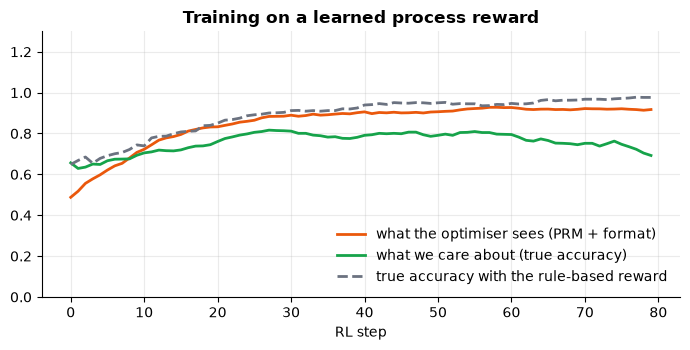

held-out accuracy: PRM reward 0.603   rule-based reward 0.973


In [30]:
def prm_reward(par, problem):
    s = prm_step_scores([par], [problem])[0]
    return (float(np.mean(s)) if s else 0.0) + 0.2 * float(par["format_ok"])          # PRM score of the steps + format; no answer check

PRMRL, h_prm, _ = run_or_load("prm_reward_d96", BASE, reward_fn=prm_reward, steps=80, lr=2e-4)
# the PRM score the optimiser saw, and the TRUE accuracy of the same samples, along training
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(curve(h_prm, "reward"), color=COLORS["value"], lw=2, label="what the optimiser sees (PRM + format)")
ax.plot(curve(h_prm, "acc"), color=COLORS["reward"], lw=2, label="what we care about (true accuracy)")
ax.plot(curve(h_zero[:80], "acc"), color=COLORS["reference"], lw=2, ls="--", label="true accuracy with the rule-based reward")
ax.set_xlabel("RL step"); ax.set_ylim(0, 1.3); ax.legend(loc="lower right"); ax.set_title("Training on a learned process reward"); plt.tight_layout(); plt.show()
fin_prm = evaluate_policy(PRMRL, tok)
print(f"held-out accuracy: PRM reward {fin_prm['acc']:.3f}   rule-based reward {final['acc']:.3f}")

**🧪 Finding.** Three things, one of them a surprise.

* The PRM is a weak classifier: at a 0.5 threshold it is right on 86.5 % of held-out steps, which is *less* than the 87.8 % you would get by calling every step correct. It has learned little beyond the base rate (we gave it noisy labels and a few thousand examples).
* Yet its *probabilities* are informative: used to rerank, it lifts accuracy from 0.595 (random pick) to 0.707, matching the paper's remark that a PRM is good "to rerank the top-N responses". A perfect picker would reach 0.993, so most of the gap is still on the table.
* As the **training reward** it is the wrong tool: the optimiser learns the format bonus (template adherence rises) but true accuracy ends at 0.60 versus 0.97 with the rule-based reward. We did *not* see dramatic reward hacking, and ⚠️ part of this is by construction, because this reward never looks at the final answer. The honest conclusion is narrower than the paper's: a noisy learned step-scorer gives the optimiser a signal that is correlated with correctness only weakly, and the optimiser has no way to know that. 💭 The extra cost (a second model to train and keep honest) buys nothing here that the checkable rule does not give for free.

### 12.2 Monte Carlo Tree Search (MCTS)

AlphaGo and AlphaZero beat humans by **searching**: at each move, explore a tree of continuations, guided by a learned *value* network that says how good a position is. 📄 R1's authors tried the same on text: "we first use collected prompts to find answers via MCTS guided by a pre-trained value model. Subsequently, we use the resulting question-answer pairs to train both the actor model and the value model, iteratively refining the process." Two problems stopped them:

1. "unlike chess, where the search space is relatively well-defined, token generation presents an exponentially larger search space."
2. "the value model directly influences the quality of generation [...] Training a fine-grained value model is inherently difficult".

The first is arithmetic, and it is worth seeing the numbers:

In [31]:
import math
V, L = tok.vocab_size, 40
print(f"our toy: {V} tokens, answers up to ~{L} tokens  ->  about 10^{L * math.log10(V):.0f} possible answers")
for k in (2, 4):
    print(f"   even if search keeps only the top {k} continuations per node: {k}^{26} = {float(k) ** 26:.1e} leaves for a typical 26-token answer")
print("a real model: ~10^5 tokens, thousands of tokens per answer ->  10^(5 x 2000) = 10^10000 possible answers")

our toy: 23 tokens, answers up to ~40 tokens  ->  about 10^54 possible answers
   even if search keeps only the top 2 continuations per node: 2^26 = 6.7e+07 leaves for a typical 26-token answer
   even if search keeps only the top 4 continuations per node: 4^26 = 4.5e+15 leaves for a typical 26-token answer
a real model: ~10^5 tokens, thousands of tokens per answer ->  10^(5 x 2000) = 10^10000 possible answers


For the second, we can *measure* how hard it is to value a half-written answer in our toy. We train a value model (a small transformer with a scalar head) to predict, at every position, whether the answer being written will turn out right, and check how well it ranks good against bad prefixes (the **AUC**: 0.5 means no better than a coin, 1.0 means perfect):

748 responses of at least 24 tokens, 78% of them correct


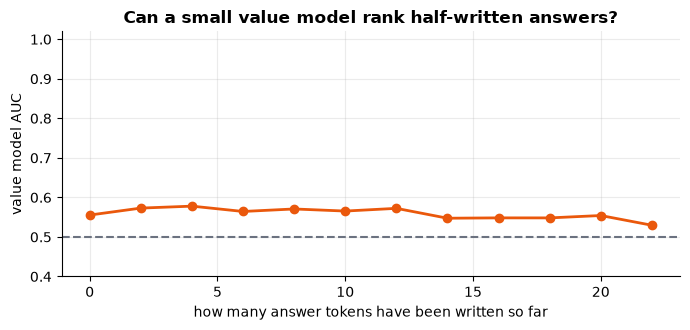

AUC after 0, 2, 4, ... tokens: [np.float64(0.56), np.float64(0.57), np.float64(0.58), np.float64(0.56), np.float64(0.57), np.float64(0.57), np.float64(0.57), np.float64(0.55), np.float64(0.55), np.float64(0.55), np.float64(0.55), np.float64(0.53)]


In [32]:
def auc(scores, labels):
    """Probability that a random positive outscores a random negative (rank-based, ties count half)."""
    s, y = np.asarray(scores, float), np.asarray(labels, bool)
    if y.all() or (~y).all(): return float("nan")
    order = s.argsort(); ranks = np.empty(len(s)); ranks[order] = np.arange(1, len(s) + 1)
    for v in np.unique(s):                                  # average ranks over ties
        idx = s == v; ranks[idx] = ranks[idx].mean()
    return (ranks[y].sum() - y.sum() * (y.sum() + 1) / 2) / (y.sum() * (~y).sum())

def prefix_dataset(n, seed):
    qs = ProblemSet(seed).sample(n); seqs, masks, P, parsed = rollout(BASE, tok, qs)
    y = torch.tensor([float(o["answer"] == q.gold) for o, q in zip(parsed, qs)])
    return seqs, masks, P, y

class ValueNet(nn.Module):
    def __init__(self, d=64): super().__init__(); self.lm = make_model(tok, d); self.v = ValueHead(d)
    def forward(self, ids): return self.v(self.lm(ids)[1])

vpath = CACHE / "value_d64.pt"; VN = ValueNet()
if vpath.exists():
    VN.load_state_dict(torch.load(vpath))
else:
    opt = torch.optim.Adam(VN.parameters(), lr=2e-3)
    for it in range(150):
        seq, mask, P, y = prefix_dataset(128, 100 + it)
        v = VN(seq)[:, P - 1:-1]; m = mask[:, P:]                     # value at the position BEFORE each response token
        loss = (F.binary_cross_entropy_with_logits(v, y[:, None].expand_as(v), reduction="none") * m).sum() / m.sum()
        opt.zero_grad(); loss.backward(); opt.step()
    torch.save(VN.state_dict(), vpath)
VN.eval()
seq, mask, P, y = prefix_dataset(1500, 9999)
with torch.no_grad(): v = VN(seq)[:, P - 1:-1]
m = mask[:, P:]
positions = list(range(0, 24, 2)); aucs = []
same_set = m[:, 23] > 0                                   # judge the SAME responses at every position (all >= 24 tokens long)
print(f"{int(same_set.sum())} responses of at least 24 tokens, {y[same_set].mean():.0%} of them correct")
for t in positions:
    aucs.append(auc(v[same_set, t].numpy(), y[same_set].numpy()))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(positions, aucs, "o-", color=COLORS["value"], lw=2); ax.axhline(0.5, color=COLORS["reference"], ls="--")
ax.set_xlabel("how many answer tokens have been written so far"); ax.set_ylabel("value model AUC"); ax.set_ylim(0.4, 1.02)
ax.set_title("Can a small value model rank half-written answers?"); plt.tight_layout(); plt.show()
print("AUC after 0, 2, 4, ... tokens:", [round(a, 2) for a in aucs])
assert max(aucs) < 0.8, "a small value model trained on a few thousand answers stays a weak judge of half-written answers"

**🧪 Finding.** Even in this tiny, clean world, a value model trained on a few thousand sampled answers is a **weak judge**: its AUC hovers around 0.55 (a coin is 0.5) at every position we test, including late in the answer, and it does not improve as the answer unfolds. We expected it to improve with position and it does not; we report that rather than the story we expected. What it does show is the paper's point 2 in miniature: a search is only as good as its value model, and a value model that cannot rank half-written answers cannot steer a search. AlphaGo's success rested on a value network that kept improving through self-play (📄 "this principle proves difficult to replicate in our setup"). ⚠️ Ours is small and briefly trained, so a stronger one might do better; the real difficulty (valuing free-form thoughts) is much harder than ours.

Both dead ends share a structure: each adds a **second learned model** (a PRM, a value network) whose errors the main model can exploit or inherit. R1's winning design does the opposite: one model, one program-checked reward.

## 13. Putting it together

Every row below is a model from this notebook, evaluated on the same 300 held-out problems (sampled at temperature 1, so these are honest "pass@1" numbers):

In [33]:
summary = {
    "base model (never trained to think)": base_dash,
    "R1-Zero: RL only (§5)": final,
    "cold start only (§8)": cold_dash,
    "cold start + RL (§8)": fin_cold,
    "RL + language reward (§9)": fin_lang,
    "SFT on rejection-sampled data (§10)": fin_sft,
    "no baseline, raw reward (§5 ablation)": fin_nb,
    "PRM as the reward (§12)": fin_prm,
}
print(f"{'':44s} {'accuracy':>9s} {'template':>9s} {'French':>7s} {'direct':>7s} {'length':>7s}")
for k, d in summary.items():
    print(f"{k:44s} {d['acc']:9.3f} {d['fmt']:9.3f} {d['french']:7.3f} {d['direct']:7.3f} {d['length']:7.1f}")

                                              accuracy  template  French  direct  length
base model (never trained to think)              0.626     0.846   0.125   0.342    17.1
R1-Zero: RL only (§5)                            0.973     1.000   0.263   0.017    24.7
cold start only (§8)                             0.903     0.997   0.003   0.000    24.2
cold start + RL (§8)                             0.983     1.000   0.017   0.000    24.2
RL + language reward (§9)                        0.957     0.993   0.003   0.033    24.8
SFT on rejection-sampled data (§10)              0.967     1.000   0.000   0.030    24.7
no baseline, raw reward (§5 ablation)            0.850     0.680   0.003   0.677     6.6
PRM as the reward (§12)                          0.603     0.990   0.197   0.000    27.9


**What each idea bought us in the toy, in one line each:**

| idea | what we measured |
|---|---|
| pure RL from a base model | accuracy and template adherence rise with no demonstrations (🧪 §5) |
| rule-based reward | a literal, unflatterable scorer: only checkable tasks (🧪 §2) |
| minimal template | constrain the form, not the content (📄) |
| GRPO | a critic-free baseline from the group; exactly policy gradient at ratio 1 (🧪 §4.5); without the baseline training goes the wrong way (🧪 §5) |
| thinking time grows | the lazy habit is selected away; responses lengthen (🧪 §5) |
| aha moment | a self-check habit survives only when the model can tell its slips (🧪 §6) |
| pass@1 / cons@k | sampling-based scoring; consensus > single sample (🧪 §7) |
| cold start | better starting point, readable output from step 0 (🧪 §8) |
| language reward | one extra term removes language mixing (🧪 §9) |
| rejection sampling + SFT | RL output becomes clean supervised data (🧪 §10) |
| distillation | the big model's traces teach a small student (🧪 §11) |
| PRM, MCTS | second learned models whose errors compound (🧪 §12) |

### What we did *not* show

* **Scale.** Everything above is a toy on a 40-token task. Whether any of these mechanisms behaves the same on a very large model and on competition mathematics is the paper's claim, not ours. 📄
* **Emergence from nothing.** Our base model was built to already contain each habit. RL chose among them. The paper's R1-Zero starts from a model whose abilities we cannot inspect; whether "aha" behaviour is *selected* or *invented* there is not something a toy can settle.
* **The last RL stage** (reward models for helpfulness and harmlessness) and the **non-reasoning SFT data** need human data we do not have.
* **Absolute numbers.** The paper's AIME, MATH-500 and Codeforces results are not reproduced and cannot be from a notebook; we only reproduced the *qualitative* shape of their figures.

### Where to read next in this course

* `09_grpo_family` for what came *after* GRPO (DAPO, GSPO, and why length normalisation matters).
* `14_llm_post_training_step_by_step` for the older recipes R1 is reacting to (SFT, RLHF with a learned reward model, DPO).
* `10` for RLVR in general and where it breaks.